# Diabetes Classifier Model - Notebook

Group Members: Vienna Donnelly, Xu Jiang

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import roc_auc_score, roc_curve

from computing4dc_hw5 import model
from computing4dc_hw5.engineering import LogTransform, OneHotEncode, Square
from computing4dc_hw5.toolkit import DataLoader, DropMissingRows, FillWithMean

Imported hw5 custom module successful


## Importing and data cleaning

In [2]:
REPO_ROOT = Path.cwd()
DATA_PATH = REPO_ROOT / 'src' / 'computing4dc_hw5' / 'sample_diabetes_mellitus_data.csv'
TARGET = "diabetes_mellitus"

assert DATA_PATH.resolve().exists() # confirm that the data file exists

In [3]:
# lets call an elf to help us get the data
dobby = DataLoader(data_path=DATA_PATH, target=TARGET, test_size=0.2, random_state=42)
df_train, df_test = dobby.get_data(index_col="encounter_id")

print(df_train.shape)
print(df_test.shape)
display(df_train.head())

(8000, 51)
(2000, 51)


,hospital_id,age,bmi,elective_surgery,ethnicity,gender,height,hospital_admit_source,icu_admit_source,icu_id,...,ventilated_apache,wbc_apache,aids,cirrhosis,hepatic_failure,immunosuppression,leukemia,lymphoma,solid_tumor_with_metastasis,diabetes_mellitus
encounter_id,,,,,,,,,,,,,,,,,,,,,
147116,118,67.0,36.095742,0,Caucasian,M,195.59,NaN,Other Hospital,97,...,1,17.6,0,0,0,0,0,0,0,1
271501,118,79.0,NaN,0,Caucasian,M,167.60,Emergency Department,Accident & Emergency,92,...,1,21.8,0,0,0,0,0,0,0,0
252766,118,66.0,NaN,0,Caucasian,M,188.00,Emergency Department,Accident & Emergency,97,...,0,8.1,0,0,0,0,0,0,0,0
222262,118,71.0,26.879192,1,Caucasian,M,175.30,Operating Room,Operating Room / Recovery,92,...,0,16.4,0,0,0,0,0,0,0,1
195030,89,43.0,32.681974,0,Caucasian,M,180.34,Direct Admit,Accident & Emergency,133,...,0,NaN,0,0,0,0,0,0,0,0


In [4]:
# q6 step b: drop rows with NaN in the demographic columns
kreacher = DropMissingRows(columns=['age', 'gender', 'ethnicity'])
df_train = kreacher.transform(df_train)
df_test = kreacher.transform(df_test)

print(df_train.shape, '\n', df_test.shape, '\n')

# q6 step c: fill NaN in height and weight with the train means
winky = FillWithMean(columns=['height', 'weight', 'bmi']) # adding bmi for later use
winky.learn_from(df_train)  # learns the means from the train set only
df_train = winky.transform(df_train)
df_test = winky.transform(df_test)  # note that test is filled with the train means

print('Remembered columns and means:', '\n', vars(winky), '\n') # see what the elf remembers: its columns and the learned means

(7503, 51) 
 (1865, 51) 

Remembered columns and means: 
 {'columns': ['height', 'weight', 'bmi'], 'means': height    170.064994
weight     86.791381
bmi        29.977919
dtype: float64} 



## Adding features

In [5]:
# q6 step d: add new features
columns_before = df_train.columns.tolist() # see what columns we have before adding new features

In [6]:
# our helper for log transformation
scabbers = LogTransform(columns=['weight']) # even one column requires a list passed 
df_train = scabbers.transform(df_train)
df_test = scabbers.transform(df_test)

# our helper for squaring
hedwig = Square(columns=['age', 'bmi']) # i suspect the risk rises disproportionally with age and bmi, so we will add the squares of these two columns
df_train = hedwig.transform(df_train)
df_test = hedwig.transform(df_test)

# our helper for one-hot encoding
crookshanks = OneHotEncode(columns=['gender', 'ethnicity'])
crookshanks.learn_from(df_train) # learns the categories from the train set only
df_train = crookshanks.transform(df_train)
df_test = crookshanks.transform(df_test) # note that test is encoded with the same columns as train, even if it has a category that train didn't have

columns_after = df_train.columns.tolist()

In [7]:
# just see what are the new columns
new_columns = [c for c in columns_after if c not in columns_before]
print('New columns added:\n' + '\n'.join(new_columns))

New columns added:
log_weight
age_squared
bmi_squared
gender_F
gender_M
ethnicity_African American
ethnicity_Asian
ethnicity_Caucasian
ethnicity_Hispanic
ethnicity_Native American
ethnicity_Other/Unknown


In [8]:
# ok let's see what we've got so far
df_train.head()

,hospital_id,age,bmi,elective_surgery,ethnicity,gender,height,hospital_admit_source,icu_admit_source,icu_id,...,age_squared,bmi_squared,gender_F,gender_M,ethnicity_African American,ethnicity_Asian,ethnicity_Caucasian,ethnicity_Hispanic,ethnicity_Native American,ethnicity_Other/Unknown
encounter_id,,,,,,,,,,,,,,,,,,,,,
147116,118,67.0,36.095742,0,Caucasian,M,195.59,NaN,Other Hospital,97,...,4489.0,1302.902614,0,1,0,0,1,0,0,0
271501,118,79.0,29.977919,0,Caucasian,M,167.60,Emergency Department,Accident & Emergency,92,...,6241.0,898.675642,0,1,0,0,1,0,0,0
252766,118,66.0,29.977919,0,Caucasian,M,188.00,Emergency Department,Accident & Emergency,97,...,4356.0,898.675642,0,1,0,0,1,0,0,0
222262,118,71.0,26.879192,1,Caucasian,M,175.30,Operating Room,Operating Room / Recovery,92,...,5041.0,722.490981,0,1,0,0,1,0,0,0
195030,89,43.0,32.681974,0,Caucasian,M,180.34,Direct Admit,Accident & Emergency,133,...,1849.0,1068.111406,0,1,0,0,1,0,0,0


## Prediction time

In [9]:
feature_set = ['height', 'weight', 'bmi', 'age'] + new_columns

# q6 steps e-f: the model elf, told which columns to learn from and which one to predict
sorting_hat = model.LogisticRegressionModel(
    features=feature_set,
    target=TARGET,
    solver="newton-cholesky", # passed through **kwargs to sklearn; converges without warnings here
)
sorting_hat.train(df_train)

In [10]:
# see the model
sorting_hat.model 

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'newton-cholesky'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. so

In [11]:
# q7: predicted probabilities on the test set, added as a new column
df_test["predictions"] = sorting_hat.predict(df_test)

auc = roc_auc_score(df_test[TARGET], df_test["predictions"])
print(f"Test ROC AUC: {auc:.3f}")

df_test[[TARGET, "predictions"]].head()

Test ROC AUC: 0.683


,diabetes_mellitus,predictions
encounter_id,,
203747,0,0.079794
164450,0,0.039919
239054,0,0.082605
149461,0,0.181957
235043,1,0.464793


### ROC curve

Let's see how it looks like 

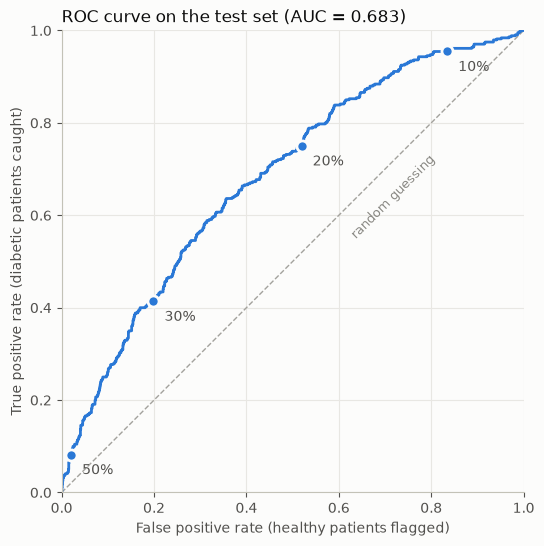

,threshold,false positive rate,true positive rate
0,0.1,0.834,0.955
1,0.2,0.519,0.750
2,0.3,0.199,0.414
3,0.5,0.020,0.082


In [12]:
fpr, tpr, thresholds = roc_curve(df_test[TARGET], df_test["predictions"])  # one (fpr, tpr) pair per threshold

fig, ax = plt.subplots(figsize=(6, 6), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
ax.plot([0, 1], [0, 1], color="#a3a29d", linewidth=1, linestyle="--")  # random guessing
ax.plot(fpr, tpr, color="#2a78d6", linewidth=2)

# mark a few thresholds on the curve, and keep their numbers for a table
marked = []
for threshold in [0.1, 0.2, 0.3, 0.5]:
    i = abs(thresholds - threshold).argmin()  # the point whose threshold is closest
    marked.append({"threshold": threshold, "false positive rate": fpr[i], "true positive rate": tpr[i]})
    ax.plot(fpr[i], tpr[i], "o", color="#2a78d6", markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=2)
    ax.annotate(f"{threshold:.0%}", (fpr[i], tpr[i]), xytext=(8, -14), textcoords="offset points", color="#52514e")

ax.text(0.62, 0.55, "random guessing", color="#8a8984", fontsize=9, rotation=45)
ax.set(xlim=(0, 1), ylim=(0, 1))
ax.set_xlabel("False positive rate (healthy patients flagged)", color="#52514e")
ax.set_ylabel("True positive rate (diabetic patients caught)", color="#52514e")
ax.set_title(f"ROC curve on the test set (AUC = {auc:.3f})", loc="left", color="#0b0b0b")
ax.set_aspect("equal")
ax.grid(color="#e8e7e3", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#c3c2b7")
ax.tick_params(colors="#52514e")
plt.show()

pd.DataFrame(marked).round(3)

<!-- sorting_hat = model.LogisticRegressionModel
sorting_hat.train(df_train)
sorting_hat -->